# 高 AI 风险时：做多 QQQ、做空 AI 等权组合——收益曲线

本 notebook 只展示多空策略的收益表现，并从项目原始小时收益和风险指数重新计算：

- 目标收益窗口：纽约时间 10:00–11:00 至 15:00–16:00。
- 信号：目标小时开始前一小时的 `AI_Risk_total`。
- 高风险：该风险值严格高于更早有效风险值的扩展 75% 分位数；阈值不包含当前信号。
- 仓位：做多 50% QQQ，做空 50% 固定 20 只 AI 股票等权组合，总敞口 100%、净敞口 0%。
- 成本：主结果按单边换手 5 bp，并在每天最后一个小时强制平仓。

QQQ 是纳斯达克 100 的代理，不是纳斯达克综合指数。


In [1]:
from pathlib import Path
import platform
import sys

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.6g}")

ROOT = Path.cwd().resolve()
AI_PATH = ROOT / "data" / "hourly_10_16" / "hourly_returns_long.csv"
QQQ_PATH = ROOT / "data" / "qqq_hourly_10_16" / "hourly_returns_long.csv"
RISK_PATH = ROOT / "data" / "hourly_ai_risk_index" / "x" / "hourly_ai_risk_index.csv"
for path in (AI_PATH, QQQ_PATH, RISK_PATH):
    if not path.exists():
        raise FileNotFoundError(path)

print("Python:", platform.python_version())
print("Interpreter:", sys.executable)
print("Project root:", ROOT)


Python: 3.14.7
Interpreter: C:\Users\Jerry Cai\Desktop\NLP_Assignment4_AI_risk_and_AI_development\.venv\Scripts\python.exe
Project root: C:\Users\Jerry Cai\Desktop\NLP_Assignment4_AI_risk_and_AI_development


## 1. 数据、严格滞后信号与组合收益


In [2]:
AI_TICKERS = (
    "MSFT", "GOOGL", "META", "AMZN", "TSLA", "ORCL", "CRM", "NOW", "ADBE", "WDAY",
    "INTU", "PATH", "AAPL", "PLTR", "UBER", "SNOW", "SHOP", "RBLX", "SNAP", "PINS",
)
PRIMARY_QUANTILE = 0.75
MIN_PRIOR_RISK_HOURS = 72
COST_BPS = 5.0


def parse_bool(series: pd.Series) -> pd.Series:
    return series.astype(str).str.strip().str.lower().eq("true")


def load_returns(path: Path) -> pd.DataFrame:
    frame = pd.read_csv(path)
    required = {
        "ticker", "trading_date", "bar_start_utc", "bar_end_utc", "duration_minutes",
        "window_complete", "ohlc_valid", "nonpositive_price", "split_event",
        "return_requires_review", "ret_oc", "source", "feed", "adjustment",
    }
    missing = required.difference(frame.columns)
    if missing:
        raise ValueError(f"{path} 缺少字段：{sorted(missing)}")
    frame["bar_start_utc"] = pd.to_datetime(frame["bar_start_utc"], utc=True)
    frame["bar_end_utc"] = pd.to_datetime(frame["bar_end_utc"], utc=True)
    frame["trading_date"] = frame["trading_date"].astype(str)
    frame["ret_oc"] = pd.to_numeric(frame["ret_oc"], errors="coerce")
    frame["duration_minutes"] = pd.to_numeric(frame["duration_minutes"], errors="coerce")
    for column in (
        "window_complete", "ohlc_valid", "nonpositive_price", "split_event", "return_requires_review"
    ):
        frame[column] = parse_bool(frame[column])
    if not frame["duration_minutes"].eq(60).all():
        raise ValueError(f"{path} 包含非 60 分钟窗口")
    if frame.duplicated(["ticker", "bar_start_utc"]).any():
        raise ValueError(f"{path} 包含重复时间戳")
    return frame


def usable_mask(frame: pd.DataFrame) -> pd.Series:
    return (
        frame["window_complete"]
        & frame["ohlc_valid"]
        & ~frame["nonpositive_price"]
        & ~frame["split_event"]
        & ~frame["return_requires_review"]
        & frame["ret_oc"].notna()
    )


ai_raw = load_returns(AI_PATH)
qqq_raw = load_returns(QQQ_PATH)
if set(ai_raw["ticker"].unique()) != set(AI_TICKERS):
    raise ValueError("AI 股票池不是指定的固定 20 只股票")
if set(qqq_raw["ticker"].unique()) != {"QQQ"}:
    raise ValueError("基准文件必须只包含 QQQ")

keys = ["trading_date", "bar_start_utc", "bar_end_utc"]
ai_usable = ai_raw.loc[usable_mask(ai_raw), keys + ["ticker", "ret_oc"]].copy()
ai_wide = ai_usable.pivot(index=keys, columns="ticker", values="ret_oc")
ai_wide = ai_wide.reindex(columns=list(AI_TICKERS))
if ai_wide.isna().any().any():
    raise ValueError("至少一个小时没有完整的 20 只 AI 股票收益")
ai_wide.columns = [f"ai_ret_{ticker}" for ticker in ai_wide.columns]
ai_wide["ai_ew_ret_oc"] = ai_wide.mean(axis=1)
ai_wide = ai_wide.reset_index()

qqq = qqq_raw.loc[usable_mask(qqq_raw), keys + ["ret_oc"]].rename(
    columns={"ret_oc": "qqq_ret_oc"}
)
if len(qqq) != len(qqq_raw):
    raise ValueError("至少一个 QQQ 小时没有通过质量检查")

market = ai_wide.merge(qqq, on=keys, how="inner", validate="one_to_one")
if len(market) != len(ai_wide) or len(market) != len(qqq):
    raise ValueError("QQQ 与 AI 组合小时窗口不是一一对应")
market = market.sort_values("bar_start_utc").reset_index(drop=True)
market["bar_start_ny"] = market["bar_start_utc"].dt.tz_convert("America/New_York")
market["bar_end_ny"] = market["bar_end_utc"].dt.tz_convert("America/New_York")
if set(market["bar_start_ny"].dt.hour.unique()) != set(range(10, 16)):
    raise ValueError("市场窗口不是纽约时间 10:00–16:00 的六个整点小时")

risk = pd.read_csv(RISK_PATH)
risk["hour"] = pd.to_datetime(risk["hour"], utc=True)
risk["AI_Risk_total"] = pd.to_numeric(risk["AI_Risk_total"], errors="coerce")
risk["observed_eligible"] = parse_bool(risk["is_backtest_eligible_observed_sample"])
risk = risk.sort_values("hour").reset_index(drop=True)
risk["eligible_risk"] = risk["AI_Risk_total"].where(risk["observed_eligible"])
risk["prior_q75"] = (
    risk["eligible_risk"].shift(1)
    .expanding(min_periods=MIN_PRIOR_RISK_HOURS)
    .quantile(PRIMARY_QUANTILE)
)

market["risk_hour"] = market["bar_start_utc"] - pd.Timedelta(hours=1)
market = market.merge(
    risk[["hour", "eligible_risk", "prior_q75"]].rename(columns={"hour": "risk_hour"}),
    on="risk_hour", how="left", validate="many_to_one",
)
market["threshold_available"] = market["prior_q75"].notna()
market["signal_ready"] = market["eligible_risk"].notna() & market["prior_q75"].notna()
market["high_risk"] = market["signal_ready"] & market["eligible_risk"].gt(market["prior_q75"])
market["signal_missing"] = market["threshold_available"] & ~market["signal_ready"]
if not (market["risk_hour"] + pd.Timedelta(hours=1)).eq(market["bar_start_utc"]).all():
    raise AssertionError("风险信号没有严格滞后一个小时")

backtest = market.loc[market["threshold_available"]].copy().reset_index(drop=True)
audit = pd.DataFrame(
    {
        "指标": [
            "市场小时数", "交易日", "信号可判断小时", "风险缺失小时",
            "高风险持仓小时", "高风险交易日", "样本起点", "样本终点",
        ],
        "数值": [
            len(market), market["trading_date"].nunique(), int(backtest["signal_ready"].sum()),
            int(backtest["signal_missing"].sum()), int(backtest["high_risk"].sum()),
            backtest.loc[backtest["high_risk"], "trading_date"].nunique(),
            str(market["bar_start_ny"].min()), str(market["bar_end_ny"].max()),
        ],
    }
)
display(audit)


,指标,数值
0,市场小时数,138
1,交易日,23
2,信号可判断小时,100
3,风险缺失小时,8
4,高风险持仓小时,31
5,高风险交易日,14
6,样本起点,2026-09-01 10:00:00-04:00
7,样本终点,2026-10-02 16:00:00-04:00


In [3]:
AI_RETURN_COLUMNS = [f"ai_ret_{ticker}" for ticker in AI_TICKERS]
ASSET_RETURN_COLUMNS = ["qqq_ret_oc", *AI_RETURN_COLUMNS]


def apply_strategy(frame: pd.DataFrame, position: pd.Series, cost_bps: float) -> pd.DataFrame:
    result = frame.copy().reset_index(drop=True)
    result["position"] = position.astype(float).to_numpy()
    result["is_last_bar_of_day"] = result.groupby("trading_date").cumcount(ascending=False).eq(0)
    asset_returns = result[ASSET_RETURN_COLUMNS].to_numpy(dtype=float)
    target_template = np.array(
        [0.5, *([-0.5 / len(AI_TICKERS)] * len(AI_TICKERS))], dtype=float
    )

    start_turnover = np.zeros(len(result))
    closing_turnover = np.zeros(len(result))
    gross_return = np.zeros(len(result))
    long_qqq = np.zeros(len(result))
    short_ai = np.zeros(len(result))
    prior_target = np.zeros(len(target_template))
    prior_asset_returns = np.zeros(len(target_template))
    prior_portfolio_return = 0.0
    prior_day = None

    for row_number, row in result.iterrows():
        new_day = row["trading_date"] != prior_day
        if new_day:
            pretrade_weights = np.zeros(len(target_template))
        else:
            pretrade_weights = (
                prior_target * (1.0 + prior_asset_returns) / (1.0 + prior_portfolio_return)
            )

        target_weights = target_template * float(row["position"])
        start_turnover[row_number] = np.abs(target_weights - pretrade_weights).sum()
        gross_return[row_number] = float(target_weights @ asset_returns[row_number])
        long_qqq[row_number] = float(target_weights[0] * asset_returns[row_number, 0])
        short_ai[row_number] = float(target_weights[1:] @ asset_returns[row_number, 1:])

        if bool(row["is_last_bar_of_day"]) and row["position"] > 0:
            end_weights = (
                target_weights * (1.0 + asset_returns[row_number])
                / (1.0 + gross_return[row_number])
            )
            closing_turnover[row_number] = np.abs(end_weights).sum()

        prior_target = target_weights
        prior_asset_returns = asset_returns[row_number]
        prior_portfolio_return = gross_return[row_number]
        prior_day = row["trading_date"]

    result["turnover"] = start_turnover + closing_turnover
    result["transaction_cost"] = result["turnover"] * cost_bps / 10_000.0
    result["strategy_gross_return"] = gross_return
    result["strategy_net_return"] = gross_return - result["transaction_cost"]
    result["long_qqq_contribution"] = long_qqq
    result["short_ai_contribution"] = short_ai
    result["gross_wealth"] = (1.0 + result["strategy_gross_return"]).cumprod()
    result["net_wealth"] = (1.0 + result["strategy_net_return"]).cumprod()
    return result


strategy = apply_strategy(backtest, backtest["high_risk"], COST_BPS)
always_on = apply_strategy(backtest, pd.Series(True, index=backtest.index), COST_BPS)
strategy["always_on_gross_wealth"] = always_on["gross_wealth"]
strategy["always_on_net_wealth"] = always_on["net_wealth"]
strategy["net_drawdown"] = (
    strategy["net_wealth"] / strategy["net_wealth"].cummax().clip(lower=1.0) - 1.0
)

daily = strategy.groupby("trading_date", sort=True).agg(
    active_hours=("position", "sum"),
    turnover=("turnover", "sum"),
)
daily["gross_return"] = strategy.groupby("trading_date")["strategy_gross_return"].apply(
    lambda values: (1.0 + values).prod() - 1.0
)
daily["net_return"] = strategy.groupby("trading_date")["strategy_net_return"].apply(
    lambda values: (1.0 + values).prod() - 1.0
)

gross_total = float(strategy["gross_wealth"].iloc[-1] - 1.0)
net_total = float(strategy["net_wealth"].iloc[-1] - 1.0)
max_drawdown = float(strategy["net_drawdown"].min())
performance = pd.DataFrame(
    {
        "指标": [
            "高风险持仓小时", "高风险交易日", "总换手",
            "费用前累计收益", "5 bp 成本后累计收益", "最大回撤",
            "做多 QQQ 的小时贡献之和", "做空 AI 组合的小时贡献之和",
        ],
        "数值": [
            int(strategy["position"].sum()),
            strategy.loc[strategy["position"].gt(0), "trading_date"].nunique(),
            float(strategy["turnover"].sum()), gross_total, net_total, max_drawdown,
            float(strategy["long_qqq_contribution"].sum()),
            float(strategy["short_ai_contribution"].sum()),
        ],
    }
)
display(performance)


,指标,数值
0,高风险持仓小时,31
1,高风险交易日,14
2,总换手,42.0404
3,费用前累计收益,-0.00376618
4,5 bp 成本后累计收益,-0.0244966
5,最大回撤,-0.0244966
6,做多 QQQ 的小时贡献之和,0.00128856
7,做空 AI 组合的小时贡献之和,-0.00504056


## 2. 收益曲线


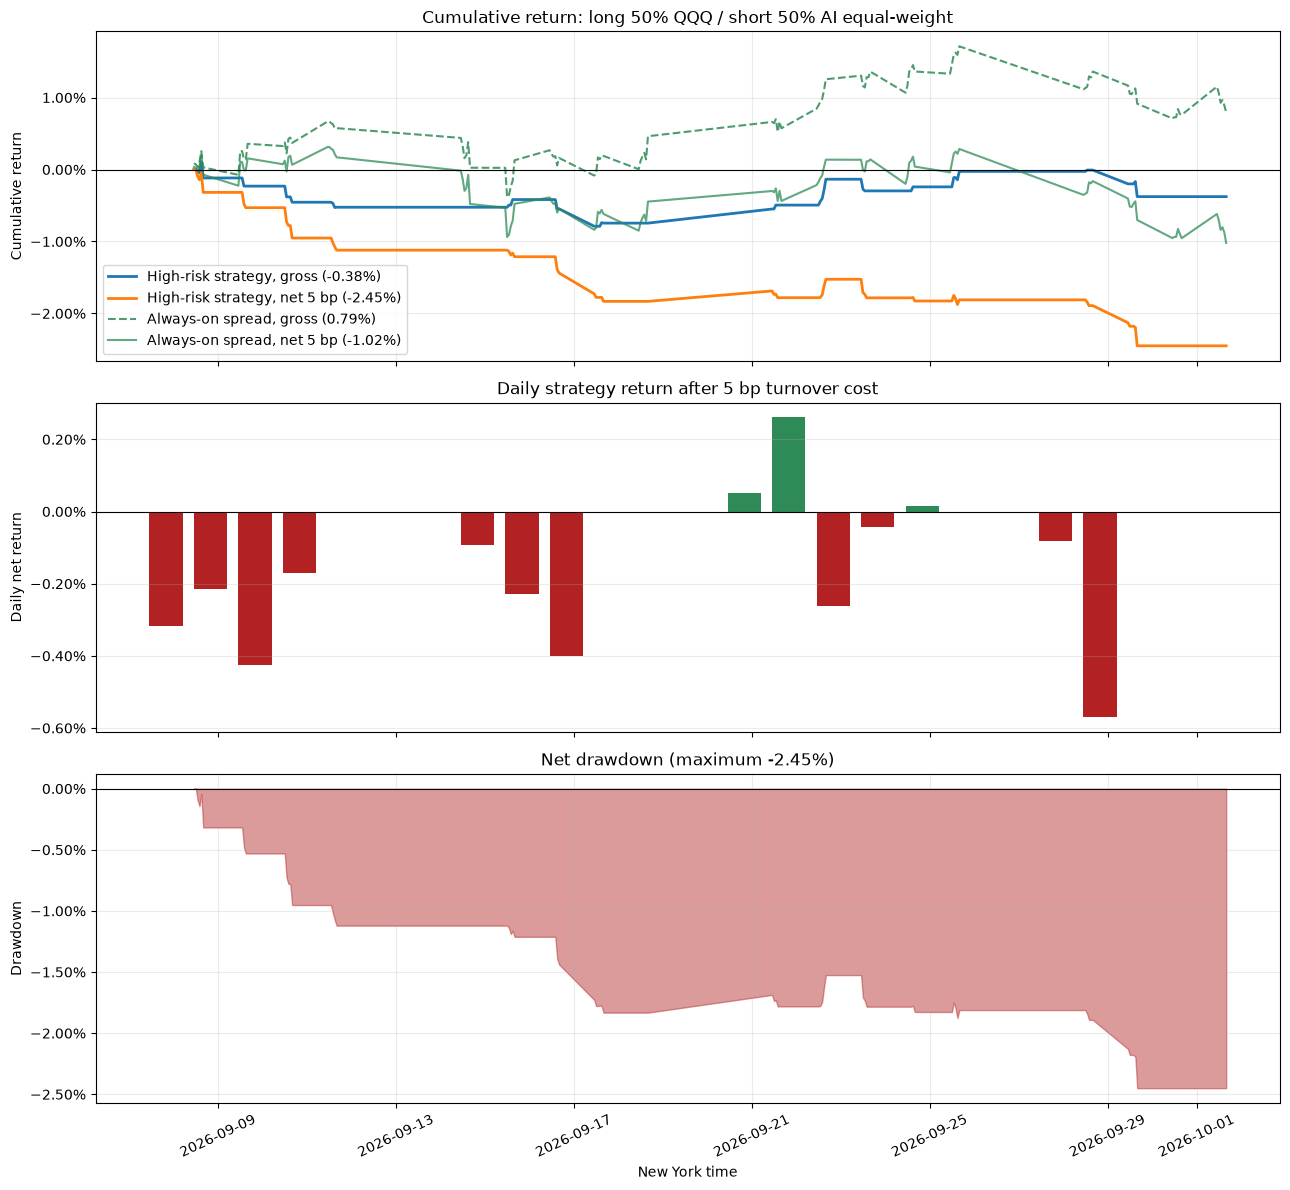

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(13, 12), sharex=True)

x = strategy["bar_end_ny"]
axes[0].plot(
    x, strategy["gross_wealth"] - 1.0, lw=2.0,
    label=f"High-risk strategy, gross ({gross_total:.2%})",
)
axes[0].plot(
    x, strategy["net_wealth"] - 1.0, lw=2.0,
    label=f"High-risk strategy, net 5 bp ({net_total:.2%})",
)
axes[0].plot(
    x, strategy["always_on_gross_wealth"] - 1.0, lw=1.5, alpha=0.85,
    color="seagreen", linestyle="--",
    label=f"Always-on spread, gross ({always_on['gross_wealth'].iloc[-1] - 1:.2%})",
)
axes[0].plot(
    x, strategy["always_on_net_wealth"] - 1.0, lw=1.5, alpha=0.75,
    color="seagreen",
    label=f"Always-on spread, net 5 bp ({always_on['net_wealth'].iloc[-1] - 1:.2%})",
)
axes[0].axhline(0.0, color="black", lw=0.8)
axes[0].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[0].set_ylabel("Cumulative return")
axes[0].set_title("Cumulative return: long 50% QQQ / short 50% AI equal-weight")
axes[0].legend(loc="best")
axes[0].grid(alpha=0.25)

daily_plot = daily.reset_index()
daily_dates = pd.to_datetime(daily_plot["trading_date"])
colors = np.where(daily_plot["net_return"].ge(0), "seagreen", "firebrick")
axes[1].bar(daily_dates, daily_plot["net_return"], color=colors, width=0.75)
axes[1].axhline(0.0, color="black", lw=0.8)
axes[1].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[1].set_ylabel("Daily net return")
axes[1].set_title("Daily strategy return after 5 bp turnover cost")
axes[1].grid(axis="y", alpha=0.25)

axes[2].fill_between(x, strategy["net_drawdown"], 0.0, color="firebrick", alpha=0.45)
axes[2].axhline(0.0, color="black", lw=0.8)
axes[2].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[2].set_ylabel("Drawdown")
axes[2].set_xlabel("New York time")
axes[2].set_title(f"Net drawdown (maximum {max_drawdown:.2%})")
axes[2].grid(alpha=0.25)

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


## 3. 图形解读

- 第一张图是核心收益曲线：四条线分别是高风险策略的成本前/成本后结果，以及 always-on 价差的成本前/成本后结果。
- 第二张图显示每天的成本后收益；没有高风险持仓但发生退出交易的日期仍会保留成本。
- 第三张图是成本后净值相对历史峰值的回撤。

当前样本中，高风险策略费用前和费用后累计收益均为负。主要拖累来自 AI 等权组合在被做空的高风险小时内上涨。样本期较短，而且风险指数只代表已观测到的 X News 样本，因此曲线用于描述本样本策略表现，不代表长期可交易规律。
